# Aprendizado de Máquina aplicado ao Projeto — Cantina Escolar

## 1. O problema investigado

O projeto simula a operação da cantina de uma escola (*Colégio Fictício Horizonte*): vendas de 27 a 29 produtos, perdas/desperdício, cardápio com reajuste de preços, clima, calendário escolar, inflação, turmas/alunos e controle de devedores, tudo gerado pelo **gerador de dados** do grupo.

Pelo próprio gerador (`perdas.py`), a cantina **produz os itens perecíveis com base na média de vendas dos últimos 5 dias**. Quando o dia foge do padrão (calor, frio, chuva, sexta-feira, início de mês, evento), sobra produto, e a sobra vira prejuízo. A pergunta do projeto é:

> **É possível prever a demanda diária de cada produto da cantina, usando clima, calendário e preço, e com isso reduzir o desperdício sem faltar produto?**

## 2. Escolha da técnica e do algoritmo

| Decisão | Escolha | Justificativa |
|---|---|---|
| Tipo de aprendizado | **Regressão** (supervisionado) | O alvo é a **quantidade de unidades vendidas** por produto em cada dia: um número contínuo, que é o que a cantina precisa para decidir quanto produzir. Classificação exigiria transformar a quantidade em faixas e perder informação. Agrupamento não tem alvo e não prevê nada. |
| Algoritmo principal | **Random Forest Regressor** | Captura **interações** (calor × bebida gelada, frio × chocolate quente, sexta × salgado) sem que a gente as programe, não exige que as relações sejam lineares, lida bem com variáveis categóricas (após One-Hot) e numéricas misturadas, é robusto a ruído (os dados têm ~3% de falhas) e permite interpretar a importância das variáveis. É o mesmo algoritmo visto nas Aulas 05 e 06, o que facilita comparar. |
| Algoritmos de comparação | Baseline (média dos últimos 5 dias, que é a regra atual da cantina), **Ridge** (linear) e **HistGradientBoosting** | Um modelo de ML só vale a pena se ganhar de uma regra simples. O Ridge mostra o que uma relação linear consegue, e o Gradient Boosting é o concorrente natural da Random Forest. |
| Validação | **Divisão temporal** (treino = passado, teste = últimos dias) e `TimeSeriesSplit` na validação cruzada | Em previsão de demanda, embaralhar os dias deixaria o modelo "ver o futuro". Aqui o teste simula o uso real. |

## 3. Roteiro do notebook

1. Carga e **limpeza** das 5 fontes de dados (todas com falhas propositais do gerador)
2. Análise exploratória e primeiros insights
3. Construção da base de modelagem (produto × dia) e engenharia de variáveis
4. Treino, comparação de modelos e ajuste de hiperparâmetros
5. Avaliação e análise dos erros
6. **Interpretação**: o que o modelo aprendeu (insights)
7. Aplicação prática: simulação de produção e desperdício
8. Conclusões e limitações

In [ ]:
import json, re, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
RANDOM_STATE = 42

## 4. Carga dos dados

Os arquivos são os gerados por `gerar_dados.py` (pasta `dados/bronze`). **Colab:** envie a pasta `dados` para o Drive e ajuste `DADOS_DIR`. **Local:** deixe a pasta `dados` ao lado do notebook.

In [ ]:
try:  # ambiente Google Colab (igual às aulas)
    from google.colab import drive
    drive.mount("/content/drive")
    DADOS_DIR = Path("/content/drive/MyDrive/Big Data/dados/bronze")
except ImportError:  # execução local
    DADOS_DIR = Path("dados/bronze")

vendas_raw = pd.read_excel(DADOS_DIR / "vendas" / "historico_vendas.xlsx")
perdas_raw = pd.read_excel(DADOS_DIR / "perdas" / "historico_perdas.xlsx")
clima_raw = pd.DataFrame(json.load(open(DADOS_DIR / "clima" / "clima_2026.json", encoding="utf-8"))["registros"])
cal_raw = pd.DataFrame(json.load(open(DADOS_DIR / "calendario_escolar" / "calendario_escolar_2026.json", encoding="utf-8"))["dias"])
card_raw = pd.concat(
    [pd.read_excel(f).assign(vigencia=pd.Timestamp(re.search(r"(\d{4}-\d{2}-\d{2})", f.name).group(1)))
     for f in sorted((DADOS_DIR / "cardapio").glob("cardapio_vigencia_*.xlsx"))],
    ignore_index=True)

pd.DataFrame({"fonte": ["vendas", "perdas", "clima", "calendário", "cardápio (2 vigências)"],
              "linhas": [len(vendas_raw), len(perdas_raw), len(clima_raw), len(cal_raw), len(card_raw)]})

,fonte,linhas
0,vendas,16247
1,perdas,1736
2,clima,308
3,calendário,365
4,cardápio (2 vigências),54


## 5. Limpeza e tratamento dos dados

O gerador injeta ~3% de falhas de propósito, como acontece em dados reais. Cada falha abaixo foi **identificada nos dados**, não só lida no código do gerador, e cada tratamento foi escolhido para **não inventar informação**: quando dá para recuperar o valor correto por outra coluna, recupera; quando não dá, descarta.

### 5.1 Cardápio (preços, custos e categorias)
Falhas: preço sem vírgula (×100), custo ausente ou negativo, nomes com caixa/espaços errados, categoria digitada errada.

In [ ]:
CATEGORIAS = ["Salgados", "Lanches Naturais", "Bebidas", "Doces", "Sobremesas"]

def categoria_canonica(x):
    """Corrige 'salgados', 'SALGADOS', 'Salgado', 'Bebida'... para o nome oficial."""
    if pd.isna(x): return np.nan
    t = str(x).strip().lower()
    for c in CATEGORIAS:
        if c.lower() == t or c.lower().startswith(t) or t.startswith(c.lower()):
            return c
    return np.nan

card = card_raw.copy()
log_card = {}
card["nome_produto"] = card["nome_produto"].astype(str).str.strip()
card["categoria"] = card["categoria"].map(categoria_canonica)

# preço ×100 (ex.: 600,00 em vez de 6,00)
mask = card["preco_venda"] > 100
log_card["preço com vírgula perdida (÷100)"] = int(mask.sum())
card.loc[mask, "preco_venda"] = card.loc[mask, "preco_venda"] / 100

# custo negativo -> valor absoluto ; custo ausente -> razão custo/preço do próprio produto
mask = card["custo_unitario"] < 0
log_card["custo negativo (|x|)"] = int(mask.sum())
card.loc[mask, "custo_unitario"] = card.loc[mask, "custo_unitario"].abs()
razao_cat = (card["custo_unitario"] / card["preco_venda"]).groupby(card["categoria"]).transform("median")
mask = card["custo_unitario"].isna()
log_card["custo ausente (imputado pelo custo do produto na outra vigência ou razão custo/preço)"] = int(mask.sum())
# 1ª opção: custo do mesmo produto na outra vigência; 2ª (produto só em uma vigência): razão custo/preço da categoria
custo_outra_vigencia = card.groupby("id_produto")["custo_unitario"].transform("median")
card.loc[mask, "custo_unitario"] = custo_outra_vigencia.fillna(card["preco_venda"] * razao_cat)[mask].round(2)

# nome e categoria oficiais por produto (a versão não corrompida, quando existe)
nome_ok = card[~card["nome_produto"].str.isupper()].groupby("id_produto")["nome_produto"].first()
card["nome_produto"] = card["id_produto"].map(nome_ok).fillna(card["nome_produto"].str.capitalize())
cat_ok = card.dropna(subset=["categoria"]).groupby("id_produto")["categoria"].agg(lambda s: s.mode().iloc[0])
card["categoria"] = card["categoria"].fillna(card["id_produto"].map(cat_ok))
log_card["categorias ainda nulas"] = int(card["categoria"].isna().sum())

print(pd.Series(log_card, name="tratamentos no cardápio").to_string())
card.groupby("vigencia")[["preco_venda", "custo_unitario"]].describe().T.round(2).iloc[:, :4]

preço com vírgula perdida (÷100)                                                         0
custo negativo (|x|)                                                                     0
custo ausente (imputado pelo custo do produto na outra vigência ou razão custo/preço)    4
categorias ainda nulas                                                                   0


vigencia              2026-01-26  2026-07-27
preco_venda    count       27.00       27.00
               mean         5.94        6.43
               std          2.55        2.58
               min          2.00        2.50
               25%          4.00        4.50
               50%          6.00        6.00
               75%          6.75        7.50
               max         14.00       14.50
custo_unitario count       27.00       27.00
               mean         2.24        2.29
               std          1.10        1.11
               min          0.60        0.61
               25%          1.55        1.58
               50%          2.05        2.21
               75%          2.90        2.92
               max          5.50        5.57

### 5.2 Vendas
Falhas encontradas: datas como **texto** em dois formatos diferentes, **linhas duplicadas**, **produtos inexistentes** (`P999`, `P000`...), **quantidades inválidas** (0, negativas, ×10, ×100), valores unitários/totais divergentes, forma de pagamento nula ou com erro de digitação e aluno vazio.

Como o alvo do modelo é a **quantidade vendida**, o cuidado principal é com a coluna `quantidade`. Quando ela é inválida, dá para **recuperá-la** com `valor_total ÷ valor_unitario` (as duas colunas continuam corretas na mesma linha); se nem assim resultar em 1, 2 ou 3 unidades, a linha é descartada.

In [ ]:
def parse_dt(x):
    """Aceita datetime do Excel e os formatos de texto que aparecem no histórico."""
    if isinstance(x, (datetime, pd.Timestamp)):
        return pd.Timestamp(x)
    for fmt in ("%d/%m/%Y %H:%M", "%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M"):
        try:
            return pd.Timestamp(datetime.strptime(str(x).strip(), fmt))
        except ValueError:
            pass
    return pd.NaT

v = vendas_raw.copy()
log_v = {"linhas originais": len(v)}
log_v["datas em formato texto (convertidas)"] = int(v["data_hora"].map(lambda x: isinstance(x, str)).sum())
v["data_hora"] = v["data_hora"].apply(parse_dt)
log_v["datas não interpretáveis (removidas)"] = int(v["data_hora"].isna().sum())
v = v.dropna(subset=["data_hora"])

n = len(v); v = v.drop_duplicates()
log_v["registros duplicados (removidos)"] = n - len(v)

v["id_produto"] = pd.to_numeric(v["id_produto"].astype(str).str[1:], errors="coerce")
ids_validos = set(card["id_produto"])
mask = ~v["id_produto"].isin(ids_validos)
log_v["produto inexistente (removidos)"] = int(mask.sum())
v = v[~mask].copy(); v["id_produto"] = v["id_produto"].astype(int)

mask_q = ~v["quantidade"].isin([1, 2, 3])
recuperada = (v["valor_total"] / v["valor_unitario"]).round()
ok = mask_q & recuperada.isin([1, 2, 3])
v.loc[ok, "quantidade"] = recuperada[ok].astype(int)
log_v["quantidade inválida recuperada (total ÷ unitário)"] = int(ok.sum())
log_v["quantidade inválida irrecuperável (removida)"] = int((mask_q & ~ok).sum())
v = v[~(mask_q & ~ok)].copy()

# falhas que não afetam o alvo (apenas contabilizadas)
log_v["forma de pagamento nula ou com erro de digitação"] = int(
    v["forma_pagamento"].isna().sum() +
    (~v["forma_pagamento"].dropna().isin(["Dinheiro", "Pix", "Cartão de débito", "Cartão de crédito", "Fiado"])).sum())
log_v["aluno vazio"] = int(v["id_aluno"].isna().sum())
log_v["linhas finais"] = len(v)

v["data"] = v["data_hora"].dt.normalize()
print(pd.Series(log_v, name="tratamentos nas vendas").to_string())

linhas originais                                     16247
datas em formato texto (convertidas)                  2517
datas não interpretáveis (removidas)                     0
registros duplicados (removidos)                        50
produto inexistente (removidos)                         22
quantidade inválida recuperada (total ÷ unitário)       40
quantidade inválida irrecuperável (removida)             0
forma de pagamento nula ou com erro de digitação       108
aluno vazio                                             47
linhas finais                                        16175


### 5.3 Clima
Falhas: dias **sem registro**, valores **nulos**, temperaturas **absurdas** (999,9 °C, ×10, negativas), precipitação **negativa**, dias com **24 leituras horárias** (granularidade diferente) e um bloco de 5 dias com **fuso horário deslocado** (a data cai no dia anterior às 21h).

In [ ]:
c = clima_raw.copy()
log_c = {"registros originais": len(c)}

# fuso: "2026-06-14T21:00:00-03:00" é, na verdade, 15/06 00:00 (a API converteu de UTC)
tz = c["data"].str.endswith("-03:00")
c["dt"] = pd.to_datetime(c["data"].str.slice(0, 19), format="ISO8601")
c.loc[tz, "dt"] = c.loc[tz, "dt"] + pd.Timedelta(hours=3)
c["data"] = c["dt"].dt.normalize()
log_c["datas com fuso deslocado (corrigidas)"] = int(tz.sum())
log_c["leituras horárias (agregadas por dia)"] = int(c.duplicated("data", keep=False).sum())

# valores fisicamente impossíveis viram "ausente"
for col in ["temperatura_media", "temperatura_max"]:
    ruim = ~c[col].between(0, 45) & c[col].notna()
    log_c[f"{col} absurda"] = int(ruim.sum())
    c.loc[ruim, col] = np.nan
ruim = c["precipitacao_mm"] < 0
log_c["precipitação negativa"] = int(ruim.sum())
c.loc[ruim, "precipitacao_mm"] = np.nan

# várias leituras horárias -> 1 linha por dia
clima = (c.groupby("data").agg(temperatura_media=("temperatura_media", "mean"),
                               temperatura_max=("temperatura_max", "max"),
                               precipitacao_mm=("precipitacao_mm", lambda s: s.sum(min_count=1)),
                               condicao=("condicao", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan)))
clima = clima.reindex(pd.date_range(clima.index.min(), clima.index.max(), freq="D"))
log_c["dias sem nenhum registro (completados)"] = int(clima.isna().all(axis=1).sum())

# imputação: temperatura por interpolação no tempo; chuva ausente = 0; condição derivada da chuva
clima[["temperatura_media", "temperatura_max"]] = clima[["temperatura_media", "temperatura_max"]].interpolate(limit_direction="both")
clima["precipitacao_mm"] = clima["precipitacao_mm"].fillna(0.0)
sem_cond = clima["condicao"].isna()
log_c["condição ausente (derivada da precipitação)"] = int(sem_cond.sum())
clima.loc[sem_cond, "condicao"] = np.where(clima.loc[sem_cond, "precipitacao_mm"] >= 1, "chuva", "parcialmente_nublado")
clima["chuva"] = clima["condicao"].isin(["chuva", "tempestade"]).astype(int)
clima.index.name = "data"
print(pd.Series(log_c, name="tratamentos no clima").to_string())

registros originais                            308
datas com fuso deslocado (corrigidas)            5
leituras horárias (agregadas por dia)           24
temperatura_media absurda                        0
temperatura_max absurda                          4
precipitação negativa                            0
dias sem nenhum registro (completados)           2
condição ausente (derivada da precipitação)      2


### 5.4 Calendário escolar
O calendário publicado **não foi atualizado** após a greve e as reposições (a semana de greve continua como "letivo" e os sábados de reposição como "fim de semana"), além de ter feriados marcados como letivo e erros de digitação em `tipo_dia`. Por isso **não usamos o calendário para saber se houve aula**: os dias de funcionamento da cantina vêm das **próprias vendas**. Do calendário aproveitamos apenas a `descricao` (que não sofre as falhas) para marcar eventos que mudam o consumo.

In [ ]:
cal = cal_raw.copy()
cal["data"] = pd.to_datetime(cal["data"])
cal["festa_junina"] = cal["descricao"].str.contains("Festa Junina", na=False).astype(int)
cal["conselho_classe"] = cal["descricao"].str.contains("Conselho de classe", na=False).astype(int)  # sem aula à tarde
cal["quarta_cinzas"] = cal["descricao"].str.contains("Cinzas", na=False).astype(int)               # aula só à tarde
eventos = cal.set_index("data")[["festa_junina", "conselho_classe", "quarta_cinzas"]]
print("Eventos no calendário:", eventos.sum().to_dict())

dias_com_venda = pd.Series(v["data"].unique()).sort_values()
print(f"Dias com vendas: {len(dias_com_venda)} ({dias_com_venda.min():%d/%m} a {dias_com_venda.max():%d/%m/%Y})")
sem_aula_no_cal = cal[(cal["tipo_dia"].str.strip().str.lower().str.startswith("letivo")) & (~cal["data"].isin(dias_com_venda)) & (cal["data"] <= dias_com_venda.max()) & (cal["data"].dt.weekday < 5)]
print(f"Dias 'letivos' no calendário publicado SEM nenhuma venda (greve/feriados mal marcados): {len(sem_aula_no_cal)}")

Eventos no calendário: {'festa_junina': 1, 'conselho_classe': 4, 'quarta_cinzas': 1}
Dias com vendas: 153 (02/02 a 13/10/2026)
Dias 'letivos' no calendário publicado SEM nenhuma venda (greve/feriados mal marcados): 6


### 5.5 Perdas (desperdício)
Falhas: datas em formatos diferentes, produto sem correspondência, quantidade ≤ 0, motivo vazio e `valor_prejuizo` divergente. O prejuízo é **recalculado** como `quantidade × custo do cardápio vigente`, o que corrige as divergências de uma só vez.

In [ ]:
def parse_data(x):
    if isinstance(x, (datetime, pd.Timestamp)): return pd.Timestamp(x).normalize()
    for fmt in ("%d/%m/%Y", "%d-%m-%y", "%Y/%m/%d", "%Y-%m-%d"):
        try: return pd.Timestamp(datetime.strptime(str(x).strip(), fmt))
        except ValueError: pass
    return pd.NaT

p = perdas_raw.copy()
log_p = {"linhas originais": len(p)}
log_p["datas em texto (convertidas)"] = int(p["data"].map(lambda x: isinstance(x, str)).sum())
p["data"] = p["data"].apply(parse_data)
mask = ~p["id_produto"].isin(ids_validos)
log_p["produto sem correspondência (removidos)"] = int(mask.sum()); p = p[~mask]
mask = p["quantidade"] <= 0
log_p["quantidade ≤ 0 (removidos)"] = int(mask.sum()); p = p[~mask]
log_p["motivo vazio (→ 'Não informado')"] = int(p["motivo"].isna().sum())
p["motivo"] = p["motivo"].fillna("Não informado")

# custo vigente na data da perda
vigencias = sorted(card["vigencia"].unique())
def vigencia_em(d): return max([x for x in vigencias if x <= d], default=vigencias[0])
p["vigencia"] = p["data"].apply(vigencia_em)
p = p.merge(card[["vigencia", "id_produto", "custo_unitario", "categoria", "nome_produto"]], on=["vigencia", "id_produto"], how="left")
# produto descontinuado ainda perde estoque nos dias seguintes à troca: usa a versão anterior
falta = p["custo_unitario"].isna()
ult = card.sort_values("vigencia").groupby("id_produto").tail(1).set_index("id_produto")
for col, dst in [("custo_unitario", "custo_unitario"), ("categoria", "categoria"), ("nome_produto", "nome_produto")]:
    p.loc[falta, dst] = p.loc[falta, "id_produto"].map(ult[col])
p["prejuizo"] = (p["quantidade"] * p["custo_unitario"]).round(2)
log_p["prejuízo informado ≠ quantidade×custo (recalculado)"] = int((abs(p["valor_prejuizo"] - p["prejuizo"]) > 0.05).sum())
log_p["linhas finais"] = len(p)
print(pd.Series(log_p, name="tratamentos nas perdas").to_string())

linhas originais                                       1736
datas em texto (convertidas)                             10
produto sem correspondência (removidos)                  19
quantidade ≤ 0 (removidos)                               32
motivo vazio (→ 'Não informado')                         30
prejuízo informado ≠ quantidade×custo (recalculado)     144
linhas finais                                          1685


## 6. Base de modelagem: uma linha por **produto × dia**

Para cada dia em que a cantina funcionou, listamos **todos os produtos do cardápio vigente** e somamos a quantidade vendida. Produto que não vendeu nada fica com **0** (e não "sumiu" da base, senão o modelo nunca aprenderia que um produto pode ter dia ruim).

**Variáveis (features)** — só entram informações que a cantina **conhece antes de decidir a produção**:

| Grupo | Variáveis |
|---|---|
| Produto | `nome_produto`, `categoria`, `preco_venda` |
| Clima do dia (previsão) | `temperatura_media`, `temperatura_max`, `precipitacao_mm`, `chuva`, `condicao` |
| Calendário | `dia_semana`, `dia_mes`, `inicio_mes` (mesada, até dia 7), `sabado`, `festa_junina`, `conselho_classe`, `quarta_cinzas` |
| Histórico do produto | `media_5d` (média dos 5 últimos dias de funcionamento), `lag_1` (venda do dia anterior) |

As variáveis de histórico usam `shift(1)`: o dia atual **nunca** entra no próprio cálculo (evita vazamento de dados). **Alvo:** `qtd` (unidades vendidas).

In [ ]:
vend_dia_prod = v.groupby(["data", "id_produto"], as_index=False).agg(qtd=("quantidade", "sum"))
dias_op = sorted(v["data"].unique())

blocos = []
for d in dias_op:
    vig = max(x for x in vigencias if x <= d)
    itens = card[card["vigencia"] == vig][["id_produto", "nome_produto", "categoria", "preco_venda", "custo_unitario"]].copy()
    itens["data"] = d
    blocos.append(itens)
grid = pd.concat(blocos, ignore_index=True)
grid = grid.merge(vend_dia_prod, on=["data", "id_produto"], how="left")
perdido = vend_dia_prod.merge(grid[["data", "id_produto"]], how="left", indicator=True).query("_merge=='left_only'")["qtd"].sum()
grid["qtd"] = grid["qtd"].fillna(0).astype(int)
print(f"Unidades vendidas de itens fora do cardápio vigente (estoque remanescente de descontinuados, ignoradas): {int(perdido)} "
      f"({perdido / vend_dia_prod['qtd'].sum():.2%} do total)")

# clima e calendário
grid = grid.merge(clima.reset_index(), on="data", how="left").merge(eventos.reset_index(), on="data", how="left")
for col in ["festa_junina", "conselho_classe", "quarta_cinzas"]:
    grid[col] = grid[col].fillna(0).astype(int)
NOMES_DIA = {0: "seg", 1: "ter", 2: "qua", 3: "qui", 4: "sex", 5: "sab"}
grid["dia_semana"] = grid["data"].dt.weekday.map(NOMES_DIA)
grid["dia_mes"] = grid["data"].dt.day
grid["inicio_mes"] = (grid["dia_mes"] <= 7).astype(int)
grid["sabado"] = (grid["data"].dt.weekday == 5).astype(int)

# histórico por produto (somente dias anteriores)
grid = grid.sort_values(["id_produto", "data"]).reset_index(drop=True)
g = grid.groupby("id_produto")["qtd"]
grid["lag_1"] = g.shift(1)
grid["media_5d"] = g.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
grid = grid.sort_values(["data", "id_produto"]).reset_index(drop=True)

# perecível = produto que já teve "Sobra do dia" nas perdas (informação vinda dos dados)
perecivel_ids = set(p.loc[p["motivo"] == "Sobra do dia", "id_produto"])
grid["perecivel"] = grid["id_produto"].isin(perecivel_ids)

print(grid.shape, "| produtos:", grid["id_produto"].nunique(), "| dias:", grid["data"].nunique())
grid.head()

Unidades vendidas de itens fora do cardápio vigente (estoque remanescente de descontinuados, ignoradas): 20 (0.12% do total)


(4131, 22) | produtos: 29 | dias: 153


,id_produto,nome_produto,categoria,preco_venda,custo_unitario,data,qtd,temperatura_media,temperatura_max,precipitacao_mm,...,festa_junina,conselho_classe,quarta_cinzas,dia_semana,dia_mes,inicio_mes,sabado,lag_1,media_5d,perecivel
0,1,Coxinha de frango,Salgados,6.0,2.20,2026-02-02,4,24.2,28.0,23.5,...,0,0,0,seg,2,1,0,NaN,NaN,True
1,2,Pão de queijo,Salgados,4.0,1.30,2026-02-02,5,24.2,28.0,23.5,...,0,0,0,seg,2,1,0,NaN,NaN,True
2,3,Esfiha de carne,Salgados,6.0,2.30,2026-02-02,7,24.2,28.0,23.5,...,0,0,0,seg,2,1,0,NaN,NaN,True
3,4,Enroladinho de salsicha,Salgados,5.5,2.05,2026-02-02,3,24.2,28.0,23.5,...,0,0,0,seg,2,1,0,NaN,NaN,True
4,5,Pastel assado de queijo,Salgados,6.5,2.40,2026-02-02,3,24.2,28.0,23.5,...,0,0,0,seg,2,1,0,NaN,NaN,True


## 7. Análise exploratória e primeiros insights

Antes de modelar, vale ver se existe **sinal** a ser aprendido (se não houvesse, nenhum algoritmo ajudaria).

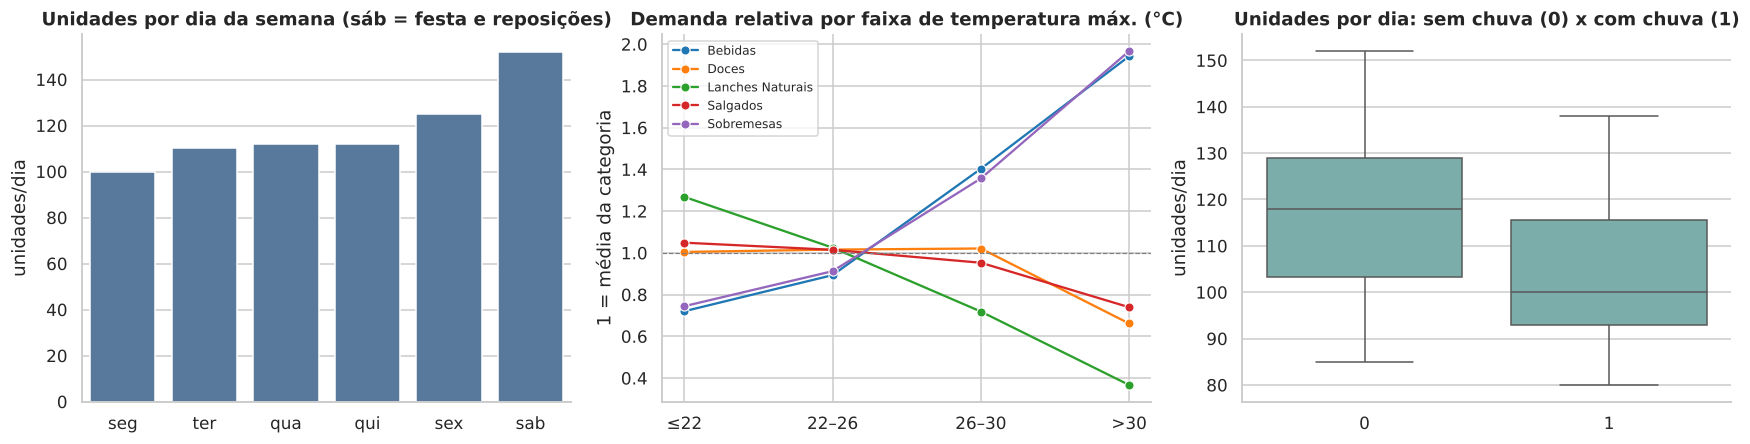

Dispersão da quantidade por linha produto×dia:
count    4131.00
mean        4.15
std         3.52
min         0.00
25%         2.00
50%         3.00
75%         6.00
max        27.00


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

# (a) venda total por dia da semana
tot_dia = grid.groupby(["data", "dia_semana"], as_index=False)["qtd"].sum()
ordem = ["seg", "ter", "qua", "qui", "sex", "sab"]
sns.barplot(data=tot_dia, x="dia_semana", y="qtd", order=ordem, color="#4C78A8", errorbar=None, ax=ax[0])
ax[0].set(title="Unidades por dia da semana (sáb = festa e reposições)", xlabel="", ylabel="unidades/dia")

# (b) demanda x temperatura, por categoria (faixas de temperatura máxima)
grid["faixa_temp"] = pd.cut(grid["temperatura_max"], [0, 22, 26, 30, 45], labels=["≤22", "22–26", "26–30", ">30"])
base = grid.groupby("categoria")["qtd"].mean()
t = grid.groupby(["faixa_temp", "categoria"])["qtd"].mean().div(base, level="categoria").reset_index()
sns.lineplot(data=t, x="faixa_temp", y="qtd", hue="categoria", marker="o", ax=ax[1], palette="tab10")
ax[1].axhline(1, color="gray", lw=0.8, ls="--")
ax[1].set(title="Demanda relativa por faixa de temperatura máx. (°C)", xlabel="", ylabel="1 = média da categoria")
ax[1].legend(fontsize=8, title=None)

# (c) chuva
ch = grid.groupby(["data", "chuva"], as_index=False)["qtd"].sum()
sns.boxplot(data=ch, x="chuva", y="qtd", color="#72B7B2", ax=ax[2])
ax[2].set(title="Unidades por dia: sem chuva (0) x com chuva (1)", xlabel="", ylabel="unidades/dia")
plt.tight_layout(); plt.show()

print("Dispersão da quantidade por linha produto×dia:")
print(grid["qtd"].describe().round(2).to_string())

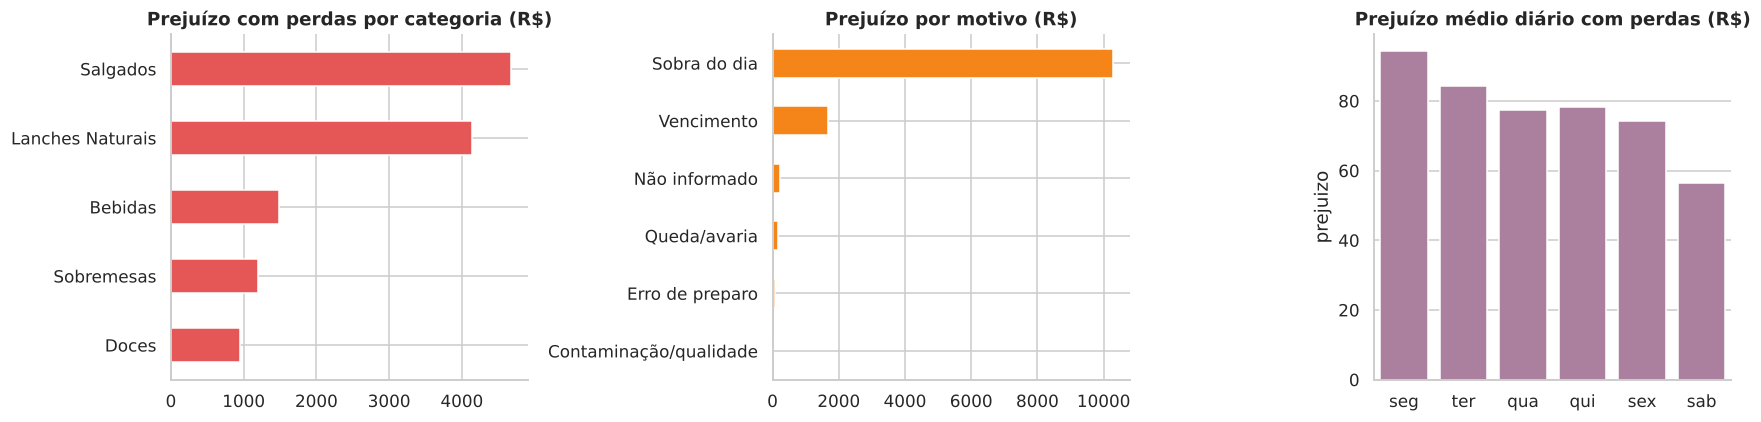

Prejuízo total registrado com perdas: R$ 12,458.20  |  82% vem de 'Sobra do dia' (produção acima da demanda)


In [ ]:
# Perdas registradas (dados limpos): quanto, onde e por quê
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
p.groupby("categoria")["prejuizo"].sum().sort_values().plot.barh(ax=ax[0], color="#E45756")
ax[0].set(title="Prejuízo com perdas por categoria (R$)", ylabel="")
p.groupby("motivo")["prejuizo"].sum().sort_values().plot.barh(ax=ax[1], color="#F58518")
ax[1].set(title="Prejuízo por motivo (R$)", ylabel="")
pd_ = p.assign(dia=p["data"].dt.weekday.map(NOMES_DIA)).groupby(["data", "dia"], as_index=False)["prejuizo"].sum()
sns.barplot(data=pd_, x="dia", y="prejuizo", order=ordem, color="#B279A2", errorbar=None, ax=ax[2])
ax[2].set(title="Prejuízo médio diário com perdas (R$)", xlabel="")
plt.tight_layout(); plt.show()
print(f"Prejuízo total registrado com perdas: R$ {p['prejuizo'].sum():,.2f}  |  "
      f"{(p[p['motivo']=='Sobra do dia']['prejuizo'].sum() / p['prejuizo'].sum()):.0%} vem de 'Sobra do dia' (produção acima da demanda)")

**O que a exploração já indica:** a demanda **muda com a temperatura** de forma diferente em cada categoria (bebidas e sobremesas geladas sobem no calor), a **sexta-feira** vende mais, e a **sobra do dia** é a principal fonte de prejuízo, justamente o tipo de perda que uma boa previsão de demanda consegue reduzir. Isso justifica o modelo.

## 8. Divisão treino/teste (temporal) e pré-processamento

Os **80% primeiros dias** são o treino e os **20% últimos** são o teste (o "futuro" que o modelo nunca viu). O pré-processamento usa a mesma estrutura de *pipeline* das aulas: imputação + padronização para numéricas e imputação + One-Hot para categóricas. Fazer isso dentro do pipeline garante que o ajuste use **só o treino**.

In [ ]:
num_feats = ["preco_venda", "temperatura_media", "temperatura_max", "precipitacao_mm", "chuva", "dia_mes",
             "inicio_mes", "sabado", "festa_junina", "conselho_classe", "quarta_cinzas", "media_5d", "lag_1"]
cat_feats = ["nome_produto", "categoria", "dia_semana", "condicao"]
FEATURES = num_feats + cat_feats

dias = np.array(sorted(grid["data"].unique()))
corte = dias[int(len(dias) * 0.8)]
treino = grid[grid["data"] < corte].copy()
teste = grid[grid["data"] >= corte].copy()
X_tr, y_tr = treino[FEATURES], treino["qtd"]
X_te, y_te = teste[FEATURES], teste["qtd"]
print(f"Treino: {treino['data'].min():%d/%m} a {treino['data'].max():%d/%m} ({treino['data'].nunique()} dias, {len(treino)} linhas)")
print(f"Teste : {teste['data'].min():%d/%m} a {teste['data'].max():%d/%m} ({teste['data'].nunique()} dias, {len(teste)} linhas)")

def preprocessador(denso=False):
    num = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    cat = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=not denso))])
    return ColumnTransformer([("num", num, num_feats), ("cat", cat, cat_feats)])

Treino: 02/02 a 20/08 (122 dias, 3294 linhas)
Teste : 21/08 a 13/10 (31 dias, 837 linhas)


## 9. Treino e comparação de modelos

Métricas (todas calculadas **no teste**):
- **MAE**: erro médio em unidades (fácil de explicar: "erra X unidades por produto/dia");
- **RMSE**: penaliza mais os erros grandes;
- **R²**: quanto da variação da demanda o modelo explica;
- **WAPE**: erro total ÷ total vendido (erro percentual ponderado, bom para contagens pequenas, onde o MAPE explode com vendas 0).

In [ ]:
def metricas(nome, y, pred):
    return {"modelo": nome, "MAE": mean_absolute_error(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R²": r2_score(y, pred), "WAPE": np.abs(y - pred).sum() / y.sum()}

resultados = []
# Baseline = regra atual da cantina: repetir a média dos últimos 5 dias
base_pred = X_te["media_5d"].fillna(y_tr.mean())
resultados.append(metricas("Baseline (média 5 dias)", y_te, base_pred))

modelos = {
    "Ridge (linear)": Pipeline([("prep", preprocessador()), ("model", Ridge(alpha=1.0))]),
    "Random Forest": Pipeline([("prep", preprocessador()), ("model", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]),
    "HistGradientBoosting": Pipeline([("prep", preprocessador(denso=True)), ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE))]),
}
for nome, pipe in modelos.items():
    pipe.fit(X_tr, y_tr)
    resultados.append(metricas(nome, y_te, pipe.predict(X_te)))

tab = pd.DataFrame(resultados).set_index("modelo").round(3)
tab

,MAE,RMSE,R²,WAPE
modelo,,,,
Baseline (média 5 dias),2.006,2.671,0.420,0.464
Ridge (linear),1.880,2.524,0.482,0.434
Random Forest,1.825,2.415,0.526,0.422
HistGradientBoosting,1.775,2.381,0.539,0.410


### 9.1 Ajuste de hiperparâmetros da Random Forest

`GridSearchCV` com `TimeSeriesSplit` (cada dobra treina no passado e valida no bloco seguinte), usando **apenas o treino**. O teste continua intocado.

In [ ]:
rf_pipe = Pipeline([("prep", preprocessador()), ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))])
grade = {"model__n_estimators": [200, 400],
         "model__max_depth": [None, 10, 20],
         "model__min_samples_leaf": [1, 3, 5],
         "model__max_features": ["sqrt", 0.5, 1.0]}
treino = treino.sort_values("data").reset_index(drop=True)   # TimeSeriesSplit respeita a ordem das linhas
busca = GridSearchCV(rf_pipe, grade, cv=TimeSeriesSplit(n_splits=4), scoring="neg_mean_absolute_error", n_jobs=-1)
busca.fit(treino[FEATURES], treino["qtd"])
print("Melhores hiperparâmetros:", busca.best_params_)
print(f"MAE médio na validação cruzada temporal: {-busca.best_score_:.3f}")

rf_final = busca.best_estimator_
pred_rf = rf_final.predict(X_te)
resultados.append(metricas("Random Forest (ajustada)", y_te, pred_rf))
tab = pd.DataFrame(resultados).set_index("modelo").round(3)
tab

Melhores hiperparâmetros: {'model__max_depth': 20, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 400}
MAE médio na validação cruzada temporal: 1.824


,MAE,RMSE,R²,WAPE
modelo,,,,
Baseline (média 5 dias),2.006,2.671,0.420,0.464
Ridge (linear),1.880,2.524,0.482,0.434
Random Forest,1.825,2.415,0.526,0.422
HistGradientBoosting,1.775,2.381,0.539,0.410
Random Forest (ajustada),1.800,2.381,0.539,0.416


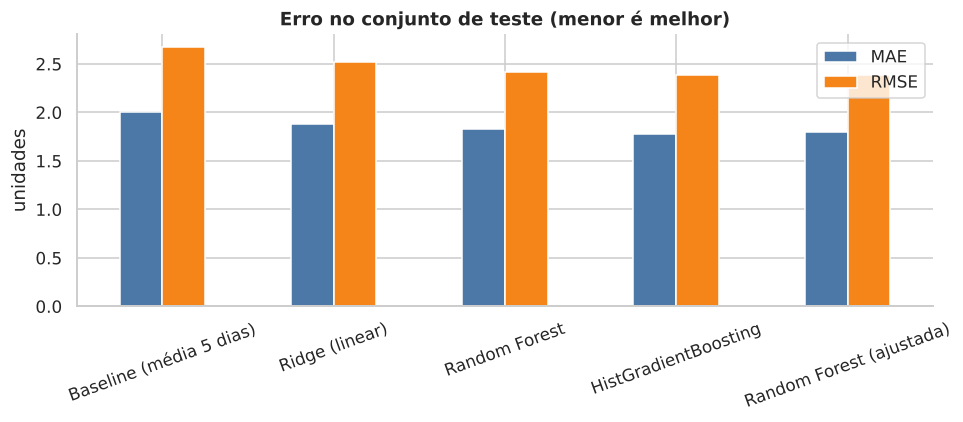

Menor MAE: HistGradientBoosting. A Random Forest ajustada reduz o erro do baseline em 10.3%.
Diferença entre a Random Forest ajustada e o melhor modelo: 0.025 unidade de MAE (empate técnico).


In [ ]:
ax = tab[["MAE", "RMSE"]].plot.bar(figsize=(9, 4), color=["#4C78A8", "#F58518"], rot=20)
ax.set(title="Erro no conjunto de teste (menor é melhor)", xlabel="", ylabel="unidades")
plt.tight_layout(); plt.show()
melhor_mae = tab["MAE"].idxmin()
ganho = 1 - tab.loc["Random Forest (ajustada)", "MAE"] / tab.loc["Baseline (média 5 dias)", "MAE"]
print(f"Menor MAE: {melhor_mae}. A Random Forest ajustada reduz o erro do baseline em {ganho:.1%}.")
dif = tab.loc["Random Forest (ajustada)", "MAE"] - tab["MAE"].min()
print(f"Diferença entre a Random Forest ajustada e o melhor modelo: {dif:.3f} unidade de MAE (empate técnico).")

## 10. Avaliação detalhada e análise dos erros

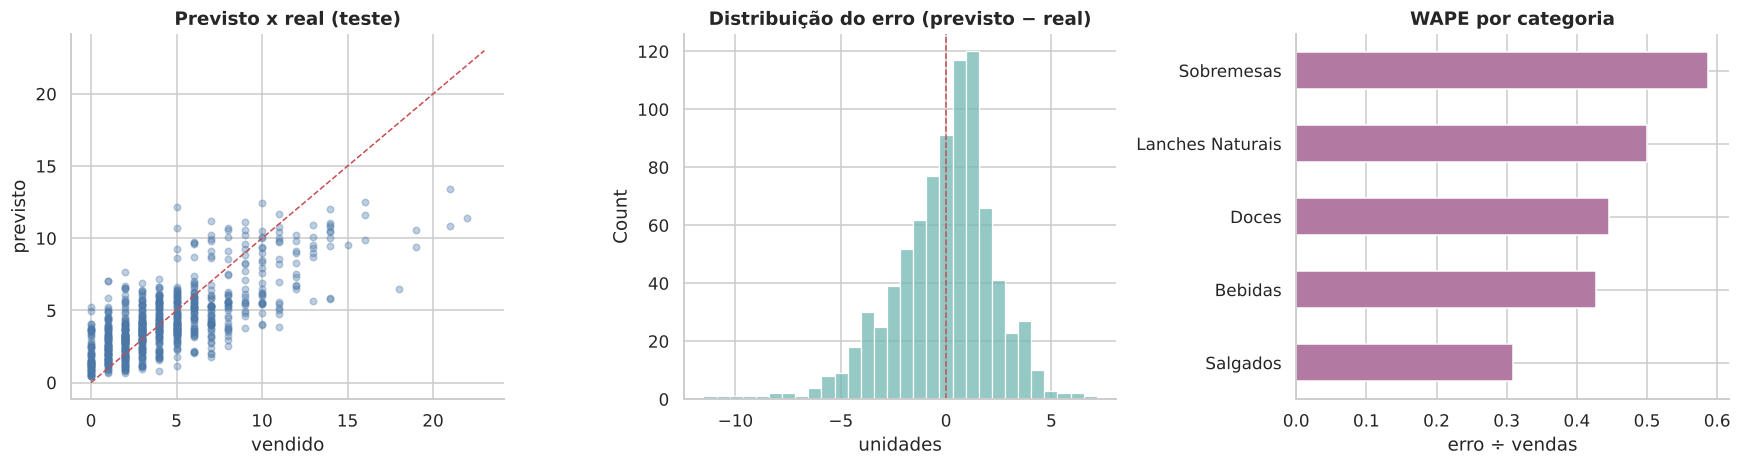

Total diário: MAE = 10.8 unidades (erro de 9.2% sobre ~117 unidades/dia)


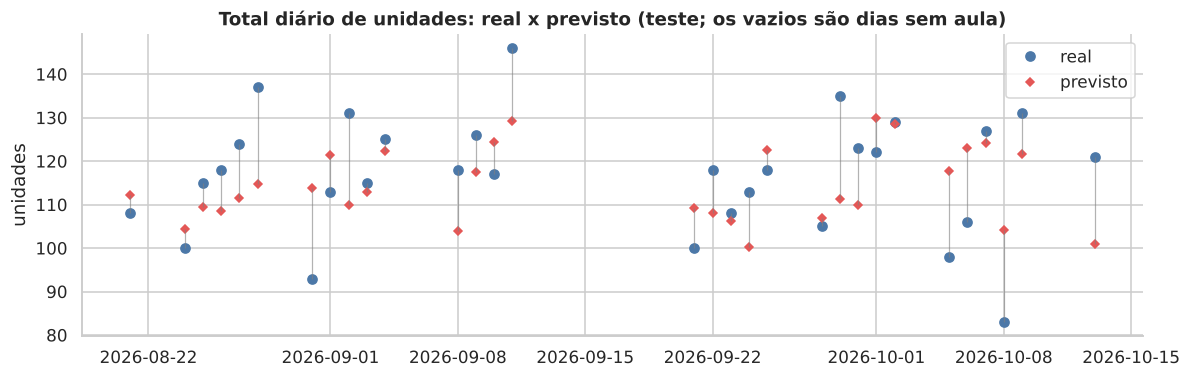

In [ ]:
teste = teste.assign(pred=pred_rf, erro=pred_rf - y_te.values)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

ax[0].scatter(teste["qtd"], teste["pred"], alpha=0.35, s=18, color="#4C78A8")
lim = max(teste["qtd"].max(), teste["pred"].max()) + 1
ax[0].plot([0, lim], [0, lim], "r--", lw=1)
ax[0].set(title="Previsto x real (teste)", xlabel="vendido", ylabel="previsto")

sns.histplot(teste["erro"], bins=30, color="#72B7B2", ax=ax[1])
ax[1].axvline(0, color="r", ls="--", lw=1)
ax[1].set(title="Distribuição do erro (previsto − real)", xlabel="unidades")

e_cat = teste.groupby("categoria").apply(lambda d: np.abs(d["erro"]).sum() / d["qtd"].sum()).sort_values()
e_cat.plot.barh(ax=ax[2], color="#B279A2")
ax[2].set(title="WAPE por categoria", ylabel="", xlabel="erro ÷ vendas")
plt.tight_layout(); plt.show()

# no nível do dia (soma de todos os produtos), onde o gestor decide
dia = teste.groupby("data")[["qtd", "pred"]].sum()
print(f"Total diário: MAE = {mean_absolute_error(dia['qtd'], dia['pred']):.1f} unidades "
      f"(erro de {np.abs(dia['qtd'] - dia['pred']).sum() / dia['qtd'].sum():.1%} sobre ~{dia['qtd'].mean():.0f} unidades/dia)")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(dia.index, dia["qtd"], "o", color="#4C78A8", label="real")
ax.plot(dia.index, dia["pred"], "D", color="#E45756", ms=4, label="previsto")
ax.vlines(dia.index, dia["qtd"], dia["pred"], color="gray", lw=0.8, alpha=0.6)
ax.legend()
ax.set(title="Total diário de unidades: real x previsto (teste; os vazios são dias sem aula)", xlabel="", ylabel="unidades")
plt.tight_layout(); plt.show()

**Leitura dos resultados.** O erro por linha produto×dia é limitado por um fator que nenhum modelo elimina: **a venda de um item em um dia é naturalmente aleatória** (quem comprou o quê depende do aluno). Por isso o R² por linha não chega perto de 1, ao contrário dos 1,0 das Aulas 05 e 06. Um resultado perfeito em dados reais é um **sinal de alerta** (costuma indicar vazamento de dados ou um alvo que é função direta de outra coluna), e não de um modelo perfeito. Aqui o desempenho é realista justamente porque o teste é feito no futuro e só entram variáveis conhecidas antes da venda. Quando somamos os produtos do dia, o erro relativo cai bastante, e é nesse nível agregado que o planejamento da cantina acontece.

## 11. Interpretação: o que o modelo aprendeu (insights)

### 11.1 Quais variáveis mais importam? (*permutation importance*)
Embaralha-se uma variável por vez no **teste** e mede-se o quanto o erro piora. Quanto maior a piora, mais o modelo depende dela.

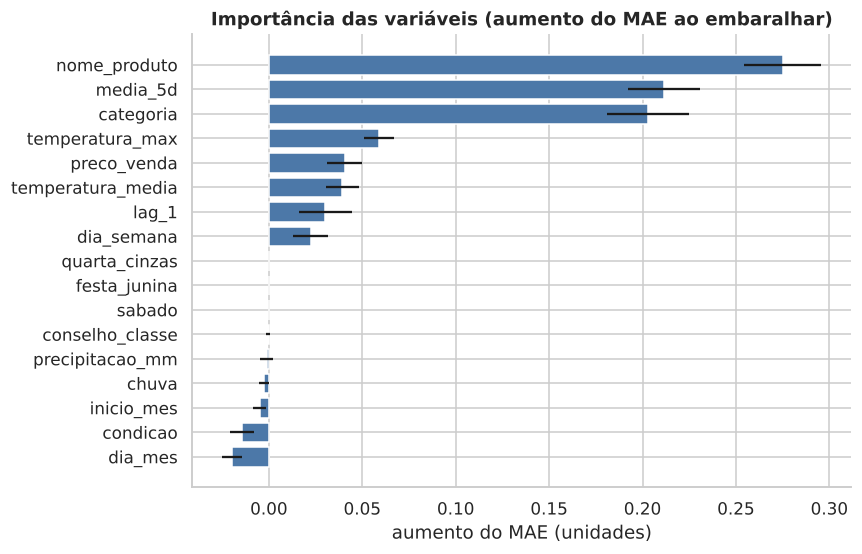

,variavel,piora_MAE,dp
0,nome_produto,0.275,0.021
1,media_5d,0.212,0.019
2,categoria,0.203,0.022
3,temperatura_max,0.059,0.008
4,preco_venda,0.041,0.009
5,temperatura_media,0.039,0.009
6,lag_1,0.030,0.014
7,dia_semana,0.022,0.009


In [ ]:
imp = permutation_importance(rf_final, X_te, y_te, n_repeats=15, random_state=RANDOM_STATE,
                             scoring="neg_mean_absolute_error", n_jobs=-1)
imp_df = pd.DataFrame({"variavel": FEATURES, "piora_MAE": imp.importances_mean, "dp": imp.importances_std}).sort_values("piora_MAE")
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(imp_df["variavel"], imp_df["piora_MAE"], xerr=imp_df["dp"], color="#4C78A8")
ax.set(title="Importância das variáveis (aumento do MAE ao embaralhar)", xlabel="aumento do MAE (unidades)")
plt.tight_layout(); plt.show()
imp_df.sort_values("piora_MAE", ascending=False).head(8).round(3).reset_index(drop=True)

### 11.2 Análise "e se...?": efeito isolado de cada fator

Usando o modelo treinado, repetimos os dias do teste **mudando só um fator** (*ceteris paribus*) e vemos quanto a previsão de cada produto muda. Isso transforma o modelo em **insight de negócio**.

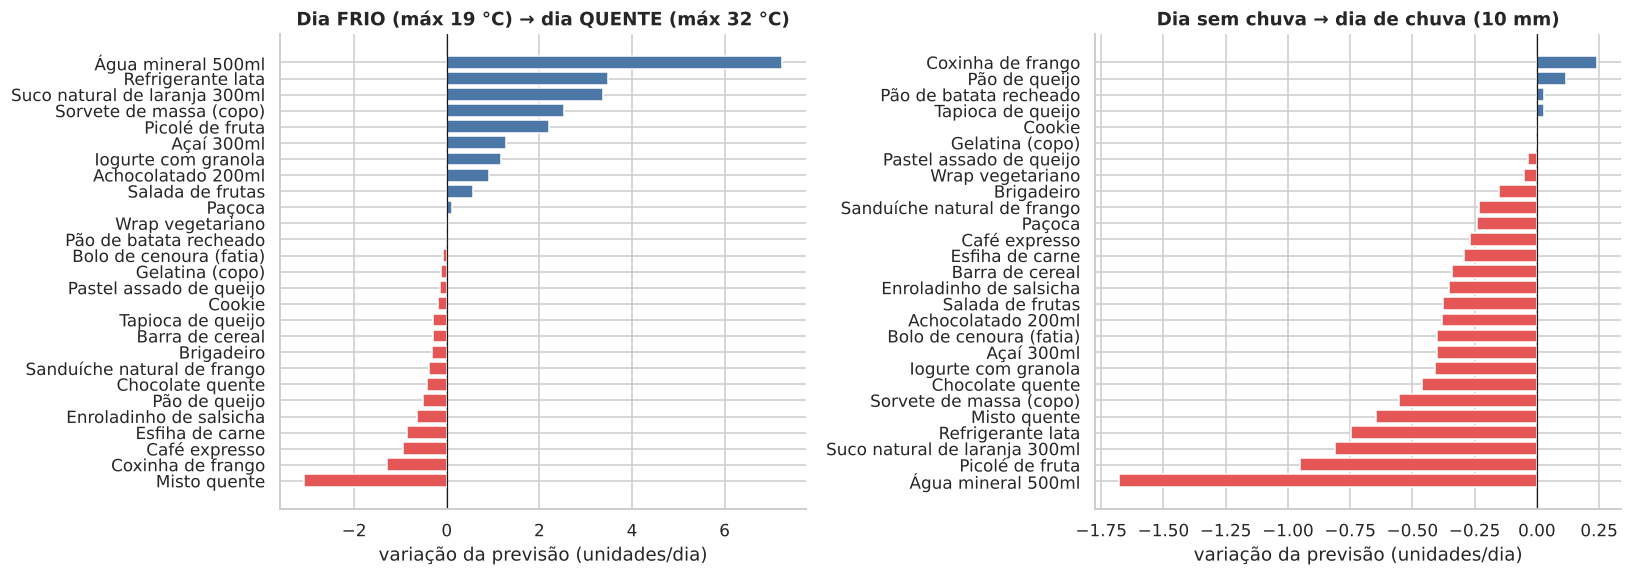

Produtos que MAIS ganham demanda no calor: ['Água mineral 500ml', 'Refrigerante lata', 'Suco natural de laranja 300ml', 'Sorvete de massa (copo)']
Produtos que MAIS perdem demanda no calor (ganham no frio): ['Misto quente', 'Coxinha de frango', 'Café expresso', 'Esfiha de carne']


Efeito total da chuva: -8.1% nas unidades vendidas por dia


Efeito total do calor sobre o volume do dia: +11.8% (o calor muda o MIX de produtos e também o volume; parte do efeito no volume pode ser coincidência de calendário)


In [ ]:
def efeito(mudancas_a, mudancas_b):
    """Previsão média por produto com o cenário B menos o cenário A (mesmos dias, só os fatores mudam)."""
    a, b = X_te.copy(), X_te.copy()
    for k, val in mudancas_a.items(): a[k] = val
    for k, val in mudancas_b.items(): b[k] = val
    d = pd.DataFrame({"produto": teste["nome_produto"].values, "a": rf_final.predict(a), "b": rf_final.predict(b)})
    r = d.groupby("produto")[["a", "b"]].mean()
    r["delta"] = r["b"] - r["a"]
    r["delta_pct"] = r["delta"] / r["a"]
    return r

frio = {"temperatura_media": 15.0, "temperatura_max": 19.0}
calor = {"temperatura_media": 26.0, "temperatura_max": 32.0}
ef_temp = efeito(frio, calor).sort_values("delta")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.4))
cores = ["#E45756" if x < 0 else "#4C78A8" for x in ef_temp["delta"]]
ax[0].barh(ef_temp.index, ef_temp["delta"], color=cores)
ax[0].axvline(0, color="k", lw=0.8)
ax[0].set(title="Dia FRIO (máx 19 °C) → dia QUENTE (máx 32 °C)", xlabel="variação da previsão (unidades/dia)")

ef_chuva = efeito({"chuva": 0, "precipitacao_mm": 0.0, "condicao": "ensolarado"},
                  {"chuva": 1, "precipitacao_mm": 10.0, "condicao": "chuva"}).sort_values("delta")
ax[1].barh(ef_chuva.index, ef_chuva["delta"], color=["#E45756" if x < 0 else "#4C78A8" for x in ef_chuva["delta"]])
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set(title="Dia sem chuva → dia de chuva (10 mm)", xlabel="variação da previsão (unidades/dia)")
plt.tight_layout(); plt.show()

print("Produtos que MAIS ganham demanda no calor:", ef_temp.tail(4).index[::-1].tolist())
print("Produtos que MAIS perdem demanda no calor (ganham no frio):", ef_temp.head(4).index.tolist())
tot_a = efeito({"chuva": 0, "precipitacao_mm": 0.0, "condicao": "ensolarado"}, {"chuva": 1, "precipitacao_mm": 10.0, "condicao": "chuva"})
print(f"Efeito total da chuva: {tot_a['b'].sum() / tot_a['a'].sum() - 1:+.1%} nas unidades vendidas por dia")
tot_t = efeito(frio, calor)
print(f"Efeito total do calor sobre o volume do dia: {tot_t['b'].sum() / tot_t['a'].sum() - 1:+.1%} "
      "(o calor muda o MIX de produtos e também o volume; parte do efeito no volume pode ser coincidência de calendário)")

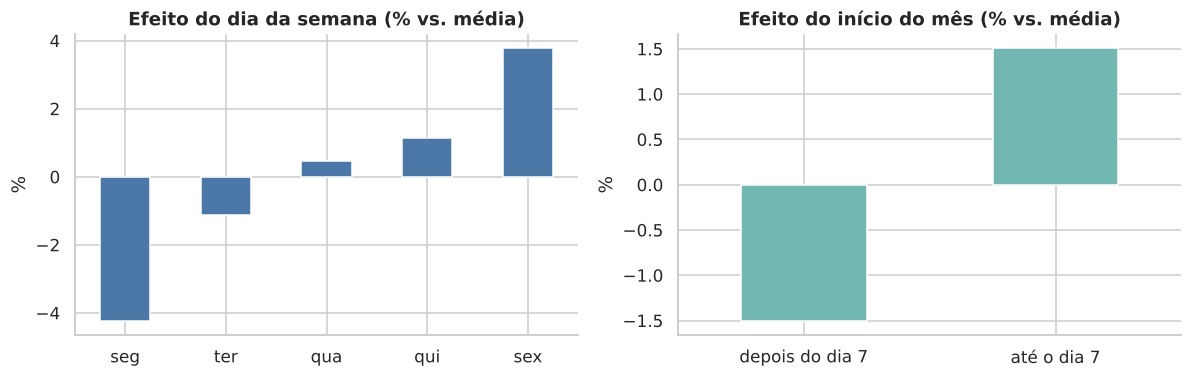

Dia da semana (% vs. média): {'seg': -4.2, 'ter': -1.1, 'qua': 0.5, 'qui': 1.1, 'sex': 3.8}
Primeira semana do mês vs. restante: +3.1%


In [ ]:
# Efeito do dia da semana e do início do mês na venda total prevista
def total_por(col, valores):
    out = {}
    for val in valores:
        x = X_te.copy(); x[col] = val
        out[val] = rf_final.predict(x).sum() / teste["data"].nunique()
    return pd.Series(out)

sem = total_por("dia_semana", ["seg", "ter", "qua", "qui", "sex"])
ini = total_por("inicio_mes", [0, 1]).rename({0: "depois do dia 7", 1: "até o dia 7"})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
(sem / sem.mean() - 1).mul(100).plot.bar(ax=ax[0], color="#4C78A8", rot=0)
ax[0].set(title="Efeito do dia da semana (% vs. média)", ylabel="%")
(ini / ini.mean() - 1).mul(100).plot.bar(ax=ax[1], color="#72B7B2", rot=0)
ax[1].set(title="Efeito do início do mês (% vs. média)", ylabel="%")
plt.tight_layout(); plt.show()
print("Dia da semana (% vs. média):", (sem / sem.mean() - 1).mul(100).round(1).to_dict())
print(f"Primeira semana do mês vs. restante: {ini['até o dia 7'] / ini['depois do dia 7'] - 1:+.1%}")

## 12. Aplicação prática: usar a previsão para decidir a produção

Para os **produtos perecíveis**, a cantina precisa decidir **quanto produzir** antes de saber quanto vai vender. Há dois tipos de erro, com custos diferentes:

- **Produzir demais** → sobra → prejuízo de `custo × unidades sobrando` (desperdício);
- **Produzir de menos** → falta → perde-se a margem `(preço − custo) × unidades que faltaram`.

Comparamos, no **mesmo período de teste e com a mesma demanda real**, três políticas de produção:

1. **Regra atual**: média dos últimos 5 dias × 1,15 + 1 (descrita em `perdas.py`);
2. **Regra atual otimizada**: a mesma ideia, com o multiplicador calibrado;
3. **Modelo de ML**: previsão da Random Forest + folga proporcional a √previsão (ruído de contagem).

Os parâmetros das políticas 2 e 3 são calibrados num **período de validação separado** (final do treino), nunca no teste, para a comparação ser honesta.

In [ ]:
def custo_politica(df, producao):
    sobra = np.clip(producao - df["qtd"], 0, None)
    falta = np.clip(df["qtd"] - producao, 0, None)
    desperdicio = (sobra * df["custo_unitario"]).sum()
    margem_perdida = (falta * (df["preco_venda"] - df["custo_unitario"])).sum()
    return {"desperdício (R$)": desperdicio, "margem perdida por falta (R$)": margem_perdida,
            "custo total (R$)": desperdicio + margem_perdida, "unidades sobrando": sobra.sum(), "unidades em falta": falta.sum()}

# validação = últimos 25% dos dias do treino
d_tr = np.array(sorted(treino["data"].unique()))
corte_val = d_tr[int(len(d_tr) * 0.75)]
tr_core, valid = treino[treino["data"] < corte_val], treino[treino["data"] >= corte_val]
rf_core = clone(rf_final).fit(tr_core[FEATURES], tr_core["qtd"])
valid = valid.assign(pred=rf_core.predict(valid[FEATURES]))
teste = teste.assign(pred=rf_final.predict(X_te))      # modelo final (treino completo)

def so_perecivel(df): return df[df["perecivel"]].copy()
vp, tp = so_perecivel(valid), so_perecivel(teste)
for d in (vp, tp):
    d["media_5d"] = d["media_5d"].fillna(d["qtd"].mean())

prod_regra = lambda d: np.round(d["media_5d"] * 1.15 + 1)
prod_regra_m = lambda d, m: np.round(d["media_5d"] * m)
prod_ml = lambda d, k: np.round(np.clip(d["pred"] + k * np.sqrt(np.clip(d["pred"], 0, None)), 0, None))

m_grid = np.arange(0.6, 1.8, 0.05)
k_grid = np.arange(-1.0, 3.01, 0.1)
m_best = min(m_grid, key=lambda m: custo_politica(vp, prod_regra_m(vp, m))["custo total (R$)"])
k_best = min(k_grid, key=lambda k: custo_politica(vp, prod_ml(vp, k))["custo total (R$)"])
print(f"Calibrado na validação -> multiplicador da regra: {m_best:.2f} | folga do ML: {k_best:.1f}·√previsão")

sim = pd.DataFrame({
    "1. Regra atual (média 5d ×1,15 +1)": custo_politica(tp, prod_regra(tp)),
    "2. Regra otimizada (média 5d ×" + f"{m_best:.2f}".replace(".", ",") + ")": custo_politica(tp, prod_regra_m(tp, m_best)),
    "3. Modelo de ML (Random Forest)": custo_politica(tp, prod_ml(tp, k_best)),
}).T
sim.round(1)

Calibrado na validação -> multiplicador da regra: 1.15 | folga do ML: 0.3·√previsão


,desperdício (R$),margem perdida por falta (R$),custo total (R$),unidades sobrando,unidades em falta
"1. Regra atual (média 5d ×1,15 +1)",2682.8,1089.5,3772.4,1153.0,257.0
"2. Regra otimizada (média 5d ×1,15)",1788.1,1765.3,3553.4,778.0,409.0
3. Modelo de ML (Random Forest),1576.0,1667.8,3243.9,667.0,396.0


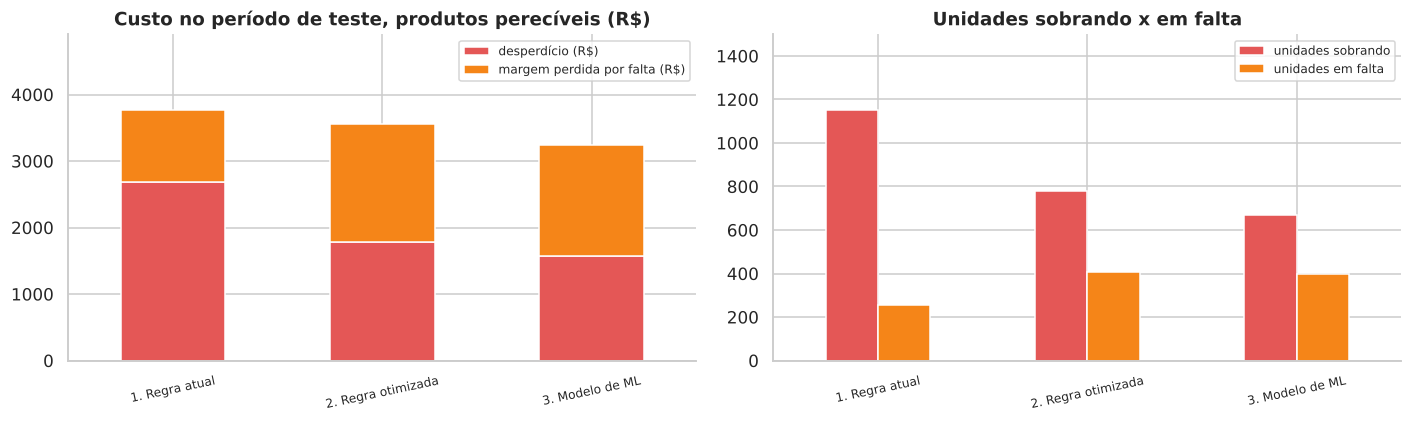

2. Regra otimizada (média 5d ×1,15): custo total 3553 R$ (-5.8% vs. regra atual) | desperdício 1788 R$ (-33.4%)
3. Modelo de ML (Random Forest): custo total 3244 R$ (-14.0% vs. regra atual) | desperdício 1576 R$ (-41.3%)

Conferência: 'Sobra do dia' realmente registrada no período de teste = R$ 2239 (simulação da regra atual = R$ 2683, mesma ordem de grandeza).


In [ ]:
base = sim.iloc[0]["custo total (R$)"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sim[["desperdício (R$)", "margem perdida por falta (R$)"]].plot.bar(stacked=True, ax=ax[0], color=["#E45756", "#F58518"], rot=12)
ax[0].set(title="Custo no período de teste, produtos perecíveis (R$)", xlabel="", ylim=(0, sim["custo total (R$)"].max() * 1.3))
ax[0].legend(loc="upper right", fontsize=8)
ax[0].set_xticklabels([l.get_text().split(" (")[0] for l in ax[0].get_xticklabels()], fontsize=8)
sim[["unidades sobrando", "unidades em falta"]].plot.bar(ax=ax[1], color=["#E45756", "#F58518"], rot=12)
ax[1].set(title="Unidades sobrando x em falta", xlabel="", ylim=(0, sim["unidades sobrando"].max() * 1.3))
ax[1].legend(loc="upper right", fontsize=8)
ax[1].set_xticklabels([l.get_text().split(" (")[0] for l in ax[1].get_xticklabels()], fontsize=8)
plt.tight_layout(); plt.show()

for nome, linha in sim.iloc[1:].iterrows():
    print(f"{nome}: custo total {linha['custo total (R$)']:.0f} R$ ({linha['custo total (R$)'] / base - 1:+.1%} vs. regra atual) | "
          f"desperdício {linha['desperdício (R$)']:.0f} R$ ({linha['desperdício (R$)'] / sim.iloc[0]['desperdício (R$)'] - 1:+.1%})")

real = p[(p["data"] >= teste["data"].min()) & (p["motivo"] == "Sobra do dia")]["prejuizo"].sum()
print(f"\nConferência: 'Sobra do dia' realmente registrada no período de teste = R$ {real:.0f} "
      f"(simulação da regra atual = R$ {sim.iloc[0]['desperdício (R$)']:.0f}, mesma ordem de grandeza).")

## 13. Conclusões

*(valores da execução com a semente 42 do gerador, dados de 02/02 a 13/10/2026; ao gerar dados novos os números mudam um pouco, a história não)*

### Desempenho do modelo
- A **Random Forest ajustada** reduziu o erro médio da regra atual da cantina (média dos 5 últimos dias) de **2,01 para 1,80 unidades** por produto/dia (**−10%**), com R² de 0,42 → 0,54. O **Ridge** (linear) ficou no meio-termo (MAE 1,88), o que confirma que há **interações** (clima × produto) que só modelos de árvores capturam bem.
- O **HistGradientBoosting** teve MAE 1,78, uma diferença de 0,025 unidade, na prática um **empate técnico**. Mantivemos a Random Forest como modelo principal por ser mais fácil de explicar e interpretar, e o resultado seria equivalente com qualquer um dos dois.
- O erro por produto/dia é limitado pela aleatoriedade natural do consumo; no **total diário** o erro cai para **~9%** (≈ 11 unidades sobre ~117 vendidas/dia).

### Insights descobertos
1. **O que mais pesa na demanda é "qual produto é" e o histórico recente** (`nome_produto`, `media_5d`, `categoria`). Entre os fatores externos, a **temperatura máxima** é a mais importante, seguida do preço (que também distingue os produtos) e do dia da semana.
2. **Calor e frio mudam o cardápio que vende.** De um dia frio (máx. 19 °C) para um quente (máx. 32 °C), o modelo prevê **+7 unidades/dia de água mineral** e aumentos em refrigerante, suco de laranja, sorvete e picolé, enquanto **misto quente (≈ −3 un./dia), coxinha, café e esfiha** vendem menos. A produção **não deve ser a mesma média todos os dias**: deve acompanhar a previsão do tempo.
3. **Chuva reduz o movimento** em cerca de **8%** das unidades do dia, puxado por bebidas geladas e sobremesas. Dia de chuva é dia de risco de **sobra**.
4. **Sexta-feira e primeira semana do mês vendem mais** (sexta ≈ +4% e segunda ≈ −4% em relação à média; primeira semana ≈ +3%). O efeito é suave no modelo porque a média dos últimos dias já carrega parte dele.
5. **A sobra do dia responde por 83% do prejuízo registrado com perdas** (R$ 12,4 mil no ano). Esse é o tipo de perda que a previsão de demanda ataca.

### Impacto prático (simulação nos 31 dias de teste, produtos perecíveis)
| Política | Desperdício | Margem perdida por falta | **Custo total** |
|---|---|---|---|
| Regra atual (média 5 d × 1,15 + 1) | R$ 2.683 | R$ 1.090 | **R$ 3.772** |
| Regra otimizada (média 5 d × 1,15) | R$ 1.788 | R$ 1.765 | **R$ 3.553** (−6%) |
| **Modelo de ML** | R$ 1.576 | R$ 1.668 | **R$ 3.244** (−14%) |

Usar a previsão do modelo **reduziu o desperdício em ~41%** e o custo total em **14%** em relação à regra atual, e em **~9%** mesmo contra uma regra simples já calibrada. **Há uma troca:** produzir mais perto da demanda aumenta as **faltas** (257 → 396 unidades no período). A folga do modelo (`k`) foi calibrada na validação para equilibrar os dois custos; se a cantina valorizar mais não faltar produto (fidelização, fila), basta aumentar `k`: as faltas caem, o desperdício sobe e o ganho diminui.

### Limitações (e como o trabalho evolui)
- **Dados sintéticos:** os padrões vêm das regras do gerador (por isso o clima aparece tão claramente). Com dados reais da cantina a mesma metodologia vale, mas os ganhos precisam ser revalidados.
- **Um único período de teste** (31 dias, 837 linhas). O ideal é repetir a avaliação em janelas móveis conforme o ano avança.
- A previsão usa o **clima do próprio dia** como se fosse conhecido; na prática, deve-se usar a **previsão do tempo**, que tem erro.
- **Venda ≠ demanda:** em dados reais, quando o produto acaba, a venda fica censurada. No gerador isso não acontece.
- O efeito do calor no **volume total** (+12%) está em parte misturado com o calendário (os meses quentes têm outro padrão de dias); o efeito no **mix de produtos** é bem mais confiável.
- **Próximos passos:** prever com intervalo (regressão quantílica) em vez de uma folga fixa; retreinar toda semana com os dados novos do gerador; e aplicar **agrupamento (K-Means)** nos alunos por perfil de consumo e **classificação** de risco de inadimplência no fiado, que usam as outras tabelas do gerador.